CONFIGURAÇÕES INICIAIS E IMPORTAÇÃO DOS DADOS

In [2]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from datetime import date

data_path = Path(r'../data/data_dummy.xlsx')

df = pd.read_excel(data_path, sheet_name = 'costumer_service')

df_incidentes = df.drop(columns = ['REQUISITANTE', 
                                   'PRIORIDADE',  
                                   'PERIODO', 
                                   'DIADASEMANA', 
                                   'TEMPODERESPOSTA', 
                                   'SLA', 
                                   'SLAATRIBUICAO'])

print(f'{'='*50}{'CABEÇALHO'}{'='*50}')
print(df_incidentes.head(5))

print('\n')
print(f'{'='*50}{'RESUMO'}{'='*50}')
print(df_incidentes.dtypes)

df_incidentes.describe()

==================================================CABEÇALHO==================================================
   TICKETID    AGENTE ECSHORTNAME    CATEGORIA     INCIDENTE     PROBLEMA  \
0   1612509  AGENTE 1     LOCAL 1  CATEGORIA 1   INCIDENTE 1   PROBLEMA 1   
1   1614167  AGENTE 1     LOCAL 1  CATEGORIA 4  INCIDENTE 27  PROBLEMA 50   
2   1614175  AGENTE 1     LOCAL 1  CATEGORIA 4  INCIDENTE 27  PROBLEMA 50   
3   1623370  AGENTE 1     LOCAL 1  CATEGORIA 4  INCIDENTE 27  PROBLEMA 50   
4   1630632  AGENTE 6     LOCAL 1  CATEGORIA 3  INCIDENTE 16  PROBLEMA 36   

     SOLUCAO NECESSARIOFIELDSERVICE            CRIADOEM         ASSOCIADOEM  \
0  SOLUCAO 1                    NaN 2026-07-01 14:05:35 2026-07-01 14:05:35   
1  SOLUCAO 8                    NaN 2026-07-03 18:25:36 2026-07-03 18:25:36   
2  SOLUCAO 8                    NaN 2026-07-03 18:35:38 2026-07-03 18:35:38   
3  SOLUCAO 8                    NaN 2026-07-16 18:50:35 2026-07-16 19:00:42   
4  SOLUCAO 7                    

,TICKETID,CRIADOEM,ASSOCIADOEM,SOLUCIONADOEM
count,6.363800e+04,63638,63638,63638
mean,1.666164e+06,2026-09-10 21:52:00.577328128,2026-09-10 22:33:32.288994048,2026-09-11 03:36:03.625679616
min,1.529015e+06,2026-03-03 16:54:03,2026-03-03 16:56:06,2026-07-01 00:08:03
25%,1.641037e+06,2026-08-10 12:56:04,2026-08-10 13:02:34.249999872,2026-08-10 16:54:24.750000128
50%,1.667304e+06,2026-09-13 23:44:34.500000,2026-09-14 00:28:24,2026-09-14 09:12:33
75%,1.691554e+06,2026-10-12 22:52:42.249999872,2026-10-12 23:37:14,2026-10-13 11:06:48.249999872
max,1.716751e+06,2026-11-12 23:49:35,2026-11-12 23:49:35,2026-11-12 23:58:42
std,2.978576e+04,NaN,NaN,NaN


CRIAÇÃO DE COLUNAS CHAVE

In [3]:


#================================COLUNA DE IDENTIFICAÇÃO DE EC================================

df_incidentes['CHAVE'] = df_incidentes.apply(
    lambda row: f"{row['ECSHORTNAME']} - {row['PISTA']}",
    axis=1) # apply é usado parea aplicar a função lambda a cada linha

#================================QUANTIFICAÇÃO FIELD================================

df_incidentes['QT_FIELD'] = df_incidentes.apply( #aqui usamos if/else como um operador ternário. Ou seja: valor_se_verdadeiro if condição else valor_se_falso
                                                #isso é usado dentro do uso de funções lambda, que não aceitam blocos de código
    lambda row_field: 1 if row_field.NECESSARIOFIELDSERVICE == 'sim' else 0, axis = 1) #lembre de colocar axis por causa da direção.
#0 é padrão PARA COLUNAS

#================================COLUNA DE TEMPO ENTRE INCIDENTES===============================

#================================QUALIDADE DA SOLUÇÃO
#Quando se avalia a qualidade de solução, descontamos aqueles que são nulos e com intervalo negativo (incidentes abertos antes da finalização do chamado anterior)

df_incidentes_qualidade = df_incidentes.copy()
#CLASSIFICAÇÃO DE ÚLTIMO INCIDENTE----------------
df_incidentes_qualidade = df_incidentes_qualidade.sort_values(by=['CHAVE', 
                                              'CRIADOEM']).reset_index(drop=True) #ordena os dados primeiro pela chave e depois por criado em.
#isso permite que seja possível idenitifcar o último incidente, sem ter que fazer algum loop e afins. Porque já vai estar sendo ordenado tanto pela data, quanto pelo nome.
#ou seja, basta olhar a linha anterior

df_incidentes_qualidade['ULTIMA_SOLUCAO'] = df_incidentes_qualidade.groupby('CHAVE')['SOLUCIONADOEM'].shift(1) #o dataframe recebe o valor da última solução na coluna ultima_solucao
#groupby para conseguirmos ver as chaves e seus últimos incidentes
#shift para olhar para a última linha e resgatar esse valor. Ou seja, pega o de cima e desloca para baixo. Se fosse 0, deslocava o da esquerda para direita.

#INTERVALO----------------
df_incidentes_qualidade['INTERVALO_INCIDENTE'] = (
    df_incidentes_qualidade['CRIADOEM'] - df_incidentes_qualidade['ULTIMA_SOLUCAO']
    ).dt.total_seconds() / 86400 #pega o total de segundos do intervalo e converte em dias

df_incidentes_qualidade['INTERVALO_INCIDENTE'] = df_incidentes_qualidade['INTERVALO_INCIDENTE'].round(2)

#FILTROS----------------
df_incidentes_qualidade = df_incidentes_qualidade.dropna(subset=['ULTIMA_SOLUCAO']) #retira todas as linhas que possuem a coluna como NaN
df_incidentes_qualidade = df_incidentes_qualidade[
    df_incidentes_qualidade['INTERVALO_INCIDENTE'] > 0
    ].reset_index(drop=True)
df_incidentes_qualidade

#================================FREQUÊNCIA DE OCORRÊNCIA
#Quando se avalia a frequência, utilizamos a coluna de Criado, desconsiderando quando a solução foi realizada. 

df_incidentes_chamados = df_incidentes.copy()


VERIFICAÇÃO DE NORMALIDADE E OUTLIERS COM RELAÇÃO A INTERVALO

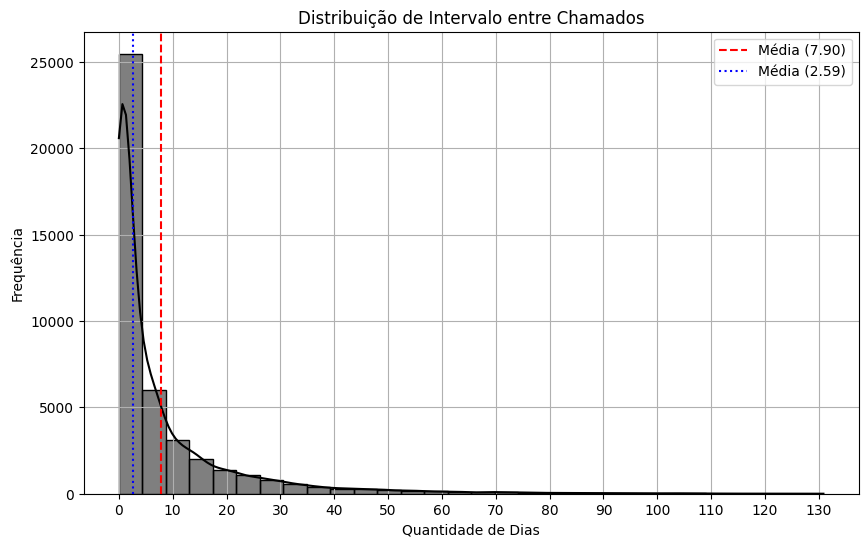

Coeficiente de assimetria: 8.985565927654608
Mediana dos dados: 2.59


In [4]:
#================================VERIFICAÇÃO DE NORMALIDADE===============================

#MEDIA E MEDIANA----------------
media_qualidade = df_incidentes_qualidade['INTERVALO_INCIDENTE'].mean()
mediana_qualidade = df_incidentes_qualidade['INTERVALO_INCIDENTE'].median()

plt.figure(figsize=(10, 6))
sns.histplot(data=df_incidentes_qualidade, 
             x='INTERVALO_INCIDENTE', 
             kde=True,
             color='black',
             bins=30)

plt.title('Distribuição de Intervalo entre Chamados')
plt.xlabel('Quantidade de Dias')
plt.ylabel('Frequência')

plt.axvline(media_qualidade, 
            color = 'r', 
            linestyle = 'dashed', 
            linewidth = 1.5,
            label=f'Média ({media_qualidade:.2f})')

plt.axvline(mediana_qualidade, 
            color = 'b', 
            linestyle = 'dotted', 
            linewidth = 1.5,
            label=f'Média ({mediana_qualidade:.2f})')

val_min = df_incidentes_qualidade['INTERVALO_INCIDENTE'].min()
val_max = df_incidentes_qualidade['INTERVALO_INCIDENTE'].max()
plt.xticks(np.arange(start=val_min, 
                     stop=val_max + 1, 
                     step=10))
plt.legend()
plt.grid(True)
plt.show()

#================================VERIFICAÇÃO DE PERCENTUAL DE OUTLIERS E NORMALIDADE===============================

#LIMITE SUPERIOR (LS) DA AMOSTRA----------------
q1 = df_incidentes_qualidade['INTERVALO_INCIDENTE'].quantile(0.25)
q3 = df_incidentes_qualidade['INTERVALO_INCIDENTE'].quantile(0.75)

#COEFICIENTE DE ASSIMETRIA----------------

assimetria_qualidade = ((q3+q1-(2*mediana_qualidade)/(q3-q1)))
print(f"Coeficiente de assimetria: {assimetria_qualidade}")
print(f"Mediana dos dados: {mediana_qualidade}")

ANÁLISE DE REINCIDÊNCIA COM BASE EM INTERVALO

In [5]:
#================================DECISÃO DE MÉDIA VS MEDIANA===============================

if assimetria_qualidade > 0 or assimetria_qualidade >= 0.5 or assimetria_qualidade <= -0.5: #analisa a possibilidade de normalidade
    
    df_incidentes_qualidade = df_incidentes_qualidade[ #se normalidade descartada com base na evidência, usar mediana para reincidência
        df_incidentes_qualidade['INTERVALO_INCIDENTE'] <= mediana_qualidade
        ].reset_index(drop=True)
    
elif assimetria_qualidade == 0:
    
    df_incidentes_qualidade = df_incidentes_qualidade[ #se normalidade sustentada com base na evidência, usar mediapara reincidência
        df_incidentes_qualidade['INTERVALO_INCIDENTE'] <= media_qualidade
        ].reset_index(drop=True)
    
else:
    
    print(f'='*100)
    print(f'Reavaliar o caso particularmente. Não houve sinais de assimetria ou simetria na amostra\n'
          f'Pode caber uma análise por valor p\nValor do coeficiente de assimetria: {assimetria_qualidade:.2f}')
    print(f'='*100)

#================================AGRUPAMENTO DOS DADOS POR DIFERENTES CONDIÇÕES===============================

reincid_qualidadeData = df_incidentes_qualidade.groupby('CHAVE').agg({ #agrupa os valores numéricos pela mediana dos valores. 
                                                                      #Os valores string são baseados na moda dos valores e resgate do primeiro lugar
    'INCIDENTE': lambda row_inc: row_inc.mode()[0],
    'PROBLEMA': lambda row_pro: row_pro.mode()[0],
    'SOLUCAO': lambda row_sol: row_sol.mode()[0],
    'AGENTE': lambda row_ag: row_ag.mode()[0],
    'INTERVALO_INCIDENTE': 'median',
    'QT_FIELD': 'sum',
})

reincid_qualidadeData_top50 = reincid_qualidadeData.copy().nsmallest(50,'INTERVALO_INCIDENTE') #nsmallest para selecionar aqueles com maior reincidência
print(reincid_qualidadeData_top50)

                           INCIDENTE     PROBLEMA    SOLUCAO    AGENTE  \
CHAVE                                                                    
LOCAL 1 - PISTA 341     INCIDENTE 27  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 377     INCIDENTE 27  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 102 - PISTA 128   INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 102 - PISTA 2234  INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 102 - PISTA 532   INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 106 - PISTA 2589  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 106 - PISTA 3078  INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 106 - PISTA 3079  INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 106 - PISTA 3080  INCIDENTE 16  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 107 - PISTA 579   INCIDENTE 14  PROBLEMA 44  SOLUCAO 7  AGENTE 6   
LOCAL 107 - PISTA 580   INCIDENTE 14  PROBLEMA 44  SOLUCAO 7  AGENTE 6   
LOCAL 107 - PISTA 584   INCIDENTE 14  

VERIFICAÇÃO DE NORMALIDADE E OUTLIERS COM RELAÇÃO A QUANTIDADE DE CHAMADOS

                         INCIDENTE     PROBLEMA    SOLUCAO    AGENTE  \
CHAVE                                                                  
LOCAL 1 - PISTA 1     INCIDENTE 27  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 1340  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 1358  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 1394  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 1 - PISTA 1601  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
...                            ...          ...        ...       ...   
LOCAL 99 - PISTA 781  INCIDENTE 28  PROBLEMA 52  SOLUCAO 7  AGENTE 1   
LOCAL 99 - PISTA 782  INCIDENTE 28  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 99 - PISTA 801  INCIDENTE 28  PROBLEMA 50  SOLUCAO 8  AGENTE 1   
LOCAL 99 - PISTA 805  INCIDENTE 28  PROBLEMA 52  SOLUCAO 7  AGENTE 8   
LOCAL 99 - PISTA 820  INCIDENTE 28  PROBLEMA 50  SOLUCAO 7  AGENTE 8   

                      QT_CHAMADOS  QT_FIELD  
CHAVE            

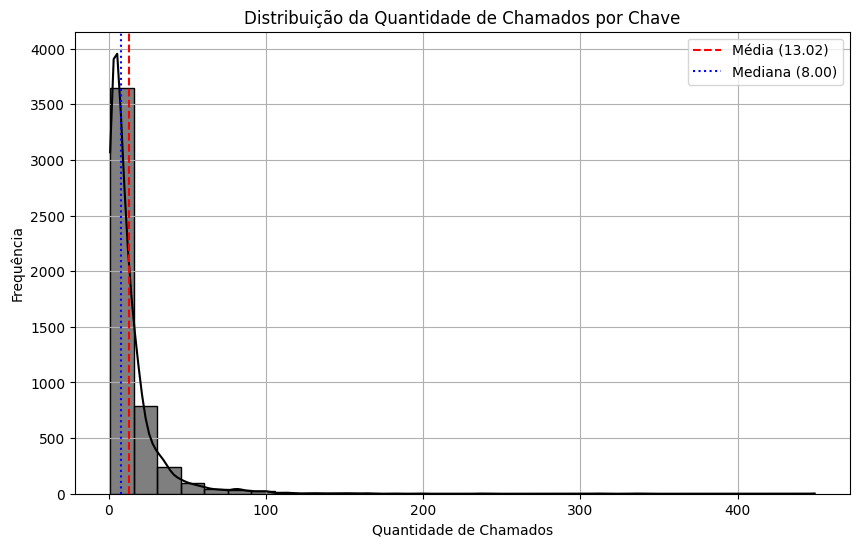

Mediana: 8.00
Coeficiente de assimetria: 0.23076923076923078


In [6]:
# ================================ CONTAGEM DE CHAMADOS POR CHAVE ================================

reincid_chamadosData = df_incidentes_chamados.groupby('CHAVE').agg({
    'INCIDENTE': lambda row_inc: row_inc.mode()[0],
    'PROBLEMA': lambda row_pro: row_pro.mode()[0],
    'SOLUCAO': lambda row_sol: row_sol.mode()[0],
    'AGENTE': lambda row_ag: row_ag.mode()[0],
    'TICKETID': 'count', #contabiliza os chamados pela chave, para conseguirmos filtrar depois pela tendência central
    'QT_FIELD': 'sum',
}).rename(columns={'TICKETID': 'QT_CHAMADOS'}) 

print(reincid_chamadosData)

# ================================ MÉDIA E MEDIANA ================================

media_chamados = reincid_chamadosData['QT_CHAMADOS'].mean()
mediana_chamados = reincid_chamadosData['QT_CHAMADOS'].median()

# ================================ PLOT DA DISTRIBUIÇÃO ================================

plt.figure(figsize=(10, 6))
sns.histplot(
    data=reincid_chamadosData,
    x='QT_CHAMADOS',
    kde=True,
    color='black',
    bins=30
)
plt.title('Distribuição da Quantidade de Chamados por Chave')
plt.xlabel('Quantidade de Chamados')
plt.ylabel('Frequência')

plt.axvline(
    media_chamados, 
    color='r', 
    linestyle='dashed', 
    linewidth=1.5,
    label=f'Média ({media_chamados:.2f})'
)
plt.axvline(
    mediana_chamados, 
    color='b', 
    linestyle='dotted', 
    linewidth=1.5,
    label=f'Mediana ({mediana_chamados:.2f})'
)

plt.legend()
plt.grid(True)
plt.show()

# ================================ VERIFICAÇÃO DE ASSIMETRIA E OUTLIERS ================================

q1_ch = reincid_chamadosData['QT_CHAMADOS'].quantile(0.25)
q3_ch = reincid_chamadosData['QT_CHAMADOS'].quantile(0.75)
iqr_ch = q3_ch - q1_ch
ls_ch = q3_ch + 1.5 * iqr_ch

over_ls_ch = (reincid_chamadosData['QT_CHAMADOS'] > ls_ch).sum()
total_chaves = reincid_chamadosData.shape[0]
outliers_pct = (over_ls_ch / total_chaves) * 100

assimetria_chamados = (q3_ch + q1_ch - (2 * mediana_chamados)) / iqr_ch if iqr_ch != 0 else 0

print(f"Mediana: {mediana_chamados:.2f}")
print(f"Coeficiente de assimetria: {assimetria_chamados}")


In [7]:
# Renomeia a coluna 'index' de volta para 'CHAVE', caso tenha perdido o nome
if 'index' in reincid_chamadosData.columns:
    reincid_chamadosData = reincid_chamadosData.rename(columns={'index': 'CHAVE'})

# ================================DECISÃO DE MÉDIA VS MEDIANA===============================
# Regra padrão: 
# |Assimetria| >= 0.5 -> Distribuição assimétrica (Usa Mediana)
# -0.5 < Assimetria < 0.5 -> Distribuição simétrica/normal (Usa Média)

if abs(assimetria_chamados) >= 0.5:
    reincid_chamadosData = reincid_chamadosData[
        reincid_chamadosData['QT_CHAMADOS'] >= mediana_chamados
    ]

elif abs(assimetria_chamados) < 0.5:
    reincid_chamadosData = reincid_chamadosData[
        reincid_chamadosData['QT_CHAMADOS'] >= media_chamados
    ]

else:
    print('=' * 100)
    print(f'Reavaliar o caso particularmente. Valor do coeficiente de assimetria: {assimetria_chamados:.2f}')
    print('=' * 100)

print('=')
print(reincid_chamadosData)

reincid_chamadoData_top50 = (
    reincid_chamadosData.nlargest(50, 'QT_CHAMADOS')
    .reset_index()
)

print(reincid_chamadoData_top50)

=
                         INCIDENTE     PROBLEMA    SOLUCAO     AGENTE  \
CHAVE                                                                   
LOCAL 1 - PISTA 1601  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 1 - PISTA 1789  INCIDENTE 14  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 1 - PISTA 342   INCIDENTE 27  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 1 - PISTA 344   INCIDENTE 14  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 1 - PISTA 41    INCIDENTE 31  PROBLEMA 64  SOLUCAO 7  AGENTE 10   
...                            ...          ...        ...        ...   
LOCAL 99 - PISTA 781  INCIDENTE 28  PROBLEMA 52  SOLUCAO 7   AGENTE 1   
LOCAL 99 - PISTA 782  INCIDENTE 28  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 99 - PISTA 801  INCIDENTE 28  PROBLEMA 50  SOLUCAO 8   AGENTE 1   
LOCAL 99 - PISTA 805  INCIDENTE 28  PROBLEMA 52  SOLUCAO 7   AGENTE 8   
LOCAL 99 - PISTA 820  INCIDENTE 28  PROBLEMA 50  SOLUCAO 7   AGENTE 8   

                      QT_CHAMADOS  QT_FIELD  
CH

EXTRAÇÃO DOS DADOS

In [9]:
from datetime import date
from pathlib import Path
import pandas as pd

ext_date = date.today()

# Função auxiliar para garantir 'CHAVE' como coluna e incluir a coluna 'DTR'
def preparar_df(df, data_execucao):
    df_temp = df.copy()
    if 'CHAVE' not in df_temp.columns:
        df_temp = df_temp.reset_index()
    df_temp['DTR'] = data_execucao
    return df_temp

data_dict = {
    'Reincidencia_Qualidade': preparar_df(reincid_qualidadeData, ext_date),
    'Reincidencia_Chamados': preparar_df(reincid_chamadosData, ext_date),
    'Reincidencia_QualidadeTop50': preparar_df(reincid_qualidadeData_top50, ext_date),
    'Reincidencia_ChamadosTop50': preparar_df(reincid_chamadoData_top50, ext_date)
}

# ================================ EXTRAÇÃO DOS DADOS UNIFICADA (ACUMULATIVA) ===============================

ext_unif = Path(r'../output')
ext_unif.mkdir(parents=True, exist_ok=True)

# Nome fixo do arquivo único
file_path = ext_unif / 'recidivism_database.xlsx'

consolidated_data = {}

for nome, df_novo in data_dict.items():
    # Se o arquivo já existir, lê os dados antigos da aba e empilha com os novos
    if file_path.exists():
        try:
            df_existente = pd.read_excel(file_path, sheet_name=nome)
            df_consolidado = pd.concat([df_existente, df_novo], ignore_index=True)
        except ValueError:
            # Caso a aba ainda não exista no arquivo
            df_consolidado = df_novo
    else:
        df_consolidado = df_novo
    
    consolidated_data[nome] = df_consolidado

# Salva todas as abas atualizadas no arquivo único
with pd.ExcelWriter(file_path, engine='xlsxwriter') as writer_xlsx:
    for nome, dados in consolidated_data.items():
        dados.to_excel(writer_xlsx, sheet_name=nome, index=False)
        worksheet = writer_xlsx.sheets[nome]
        max_row, max_col = dados.shape
        column_settings = [{'header': col} for col in dados.columns]
        worksheet.add_table(0, 0, max_row, max_col - 1, {'columns': column_settings, 'style': 'Table Style Medium 9'})
        worksheet.autofit()
        
writer_xlsx.close()

c:\Users\joaop\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xlsxwriter\workbook.py:497: UserWarning: Calling close() on already closed file.
  warn("Calling close() on already closed file.")
